In [10]:

import matplotlib.pyplot as plt
import numpy as np


import tensorflow.keras.applications

import cv2

import tensorflow as tf

from tensorflow.keras.applications.efficientnet import preprocess_input
from utils.GradientReversal import GradientReversal
from utils.LambdaScheduler import LambdaScheduler


1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


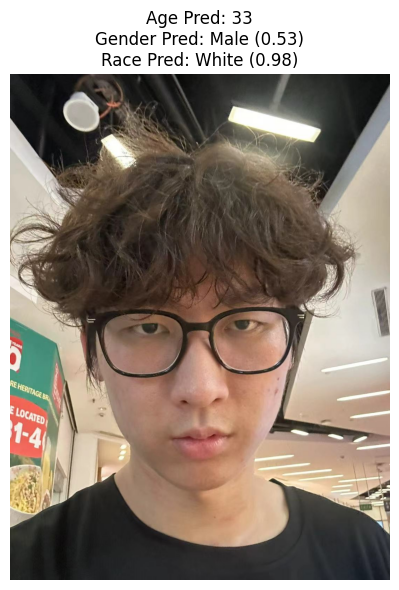

In [14]:
# Predict image from directory
def predict_and_display(image_path):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, (300, 300))
    image = preprocess_input(image)
    image = tf.expand_dims(image, axis=0)

    # model = tf.keras.models.load_model("../models/efficientnet_v2s_dev.h5")
    # model = tf.keras.models.load_model("../models/efficientnet_v2s_dev_0714.h5")
    with tf.keras.utils.custom_object_scope({'GradientReversal': GradientReversal}):
     model = tf.keras.models.load_model("../models/efficientnet_v2s_dev_reduce.h5")
    age_pred, gender_pred, race_pred = model.predict(image)
    age_pred = int(age_pred[0][0])

    raw_gender_pred = gender_pred[0][0]
    gender_pred = "Male" if raw_gender_pred < 0.5 else "Female"
    gender_confidence = 1 - raw_gender_pred if gender_pred == "Male" else raw_gender_pred

    race_labels = ["White", "Black", "Asian", "Indian", "Others"]
    race_pred_label = race_labels[np.argmax(race_pred[0])]
    race_confidence = np.max(race_pred[0])

    # Load the original image for display
    original_image = cv2.imread(image_path)
    original_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)

    # Plotting the result
    plt.figure(figsize=(6, 6))
    plt.imshow(original_image)
    plt.axis("off")
    plt.title(f"Age Pred: {age_pred}\nGender Pred: {gender_pred} ({gender_confidence:.2f})\nRace Pred: {race_pred_label} ({race_confidence:.2f})")
    plt.tight_layout()
    plt.show()

# Predict and display the result
predict_and_display('../data_test/000.jpg')